# Estudio Estadístico: Relación entre la Edad de los Usuarios y su Nivel de ELO

---

## Introducción y Contextualización del Proyecto

En el marco de la creación de nuestra plataforma web de Mus Online **Enbido.eus**, uno de los mayores desafíos técnicos y de experiencia de usuario es el **sistema de emparejamiento (matchmaking)**. Para garantizar partidas competitivas y divertidas, la plataforma debe emparejar a usuarios de habilidades similares (representadas por el sistema de puntuación **ELO**). 

Para optimizar la experiencia de nuevos usuarios de los que no tenemos historial de partidas, nos planteamos la siguiente pregunta de investigación:
**¿Existe una relación significativa entre la edad de un jugador y su nivel de habilidad (ELO) en juegos competitivos de mesa/tablero?**

Si tal relación existe y puede ser modelada matemáticamente, nuestro backend podría predecir un **ELO inicial estimado** para los nuevos usuarios basándose únicamente en su edad, ubicándolos de forma más precisa en salas acordes a su nivel y evitando la frustración de jugar contra oponentes excesivamente fuertes o débiles en sus primeras partidas.

### Origen y Naturaleza de los Datos
Al estar la plataforma de Mus online en fase de desarrollo, carecemos de millones de registros históricos. Por ello, recurrimos a dos fuentes de datos complementarias de alta confianza:

1. **Muestra Masiva**: Datos reales de ajedrez online extraídos de servidores de internet unificados. El ajedrez, al igual que el mus, es un juego mental de mesa altamente estratégico que comparte el sistema de puntuación ELO estándar y sirve como una excelente aproximacion de la evolución cognitiva y competitiva a lo largo de la vida de las personas.
2. **Encuesta**: Para validar que los patrones observados en el ajedrez son extrapolables al Mus, realizamos una encuesta/experimento piloto en nuestro entorno con **30 participantes** recopilando su edad y su conocimiento.

### Descripción de Variables
- **Edad ($X$)** [Variable Independiente / Explicativa]: Edad del usuario en años, calculada a partir de su año de nacimiento ($Edad = Año_{Estudio} - Año_{Nacimiento}$).
- **ELO ($Y$)** [Variable Dependiente / Respuesta]: Puntuación del ranking competitivo del jugador (sistema estándar FIDE / Mus).
- **Género** [Variable Dummy / Explicativa Adicional]: Género auto-reportado del jugador (1 = Masculino, 0 = Femenino), utilizado para regresión múltiple.
- **Modalidad** [Variable Explicativa Adicional]: Tipo de juego (Standard vs. Rapid vs. Blitz).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Configuración de estilo premium para gráficos
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print('Librerías cargadas correctamente.')


Librerías cargadas correctamente.


## 1. Carga de Datos y Preparación Reproducible

A continuación, realizamos la carga del dataset. Este archivo ha sido generado filtrando la base masiva original para extraer una muestra aleatoria reproducible de **5,000 jugadores activos** en el año **2021**.

Calculamos los estadísticos descriptivos básicos para comprender la estructura de las variables.


In [ ]:
# Cargar los datos del estudio masivo (Proxy de Ajedrez)
df_proxy = pd.read_csv('ratings_mus_cleaned.csv')
print(f'Muestra masiva cargada: {df_proxy.shape[0]} observaciones.')


Muestra masiva cargada: 5000 observaciones.


## 2. Análisis Exploratorio de Datos

Analizamos los estadísticos descriptivos básicos de la Edad y el ELO Estándar, y procedemos a visualizar la relación inicial mediante un **diagrama de dispersión** detallado.


=== ESTADÍSTICOS DESCRIPTIVOS - EDAD ===
count    5000.00000
mean       38.40780
std        20.12204
min        10.00000
25%        20.00000
50%        34.00000
75%        54.00000
max        90.00000
Name: age, dtype: float64

=== ESTADÍSTICOS DESCRIPTIVOS - ELO ESTÁNDAR ===
count    5000.000000
mean     1648.766800
std       347.069126
min      1001.000000
25%      1371.000000
50%      1654.000000
75%      1912.250000
max      2606.000000
Name: rating_standard, dtype: float64


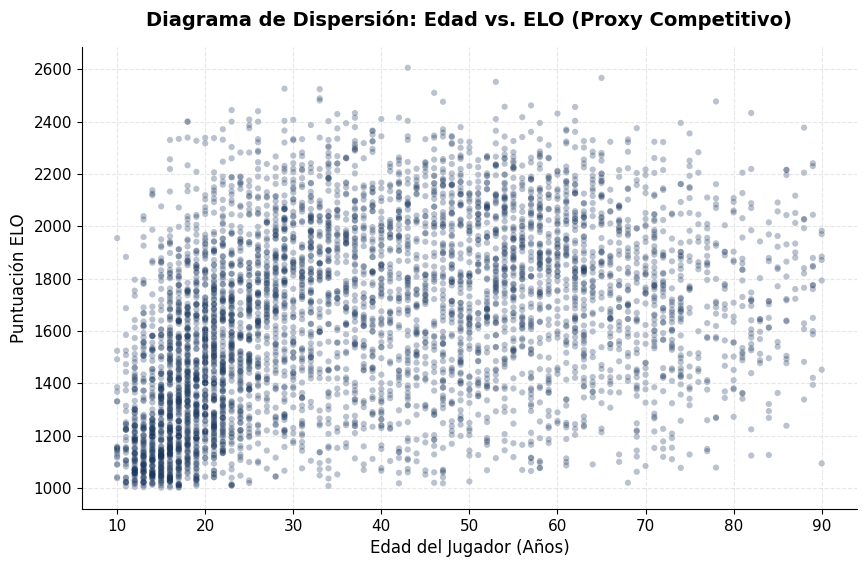

In [5]:
# Estadísticos descriptivos para las variables de estudio
print('=== ESTADÍSTICOS DESCRIPTIVOS - EDAD ===')
print(df_proxy['age'].describe())
print('\n=== ESTADÍSTICOS DESCRIPTIVOS - ELO ESTÁNDAR ===')
print(df_proxy['rating_standard'].describe())

# Diagrama de dispersión inicial
plt.scatter(df_proxy['age'], df_proxy['rating_standard'], alpha=0.3, color='#1A365D', edgecolors='none', s=20)
plt.title('Diagrama de Dispersión: Edad vs. ELO (Proxy Competitivo)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Edad del Jugador (Años)', fontsize=12)
plt.ylabel('Puntuación ELO', fontsize=12)
plt.show()


**Comentarios y Características del Diagrama de Dispersión:**

Al observar la nube de puntos del diagrama de dispersión anterior, podemos identificar las siguientes características cruciales:

1. **Dirección y Tendencia**: A primera vista, no se aprecia una tendencia lineal simple perfectamente ascendente o descendente en todo el espectro de edades. En su lugar, se intuye una tendencia de tipo **parabólica**: el ELO parece incrementarse desde los 10 hasta alcanzar un máximo alrededor de los 35-45 años, para luego iniciar un sutil declive conforme avanza la edad.
2. **Fuerza**: Existe una alta dispersión vertical del ELO para cualquier edad determinada. Esto nos indica que, aunque la edad sea un factor biológico e intelectual explicativo, la habilidad competitiva final del usuario depende también de otros factores individuales (horas de práctica, talento, experiencia, etc.). Por tanto, la relación lineal simple directa será probablemente de fuerza moderada o débil.
3. **Valores Atípicos**: La muestra se distribuye de forma bastante homogénea en un rango de ELO que va desde los 1,000 hasta los 2,800 puntos. Los jugadores con ELO superior a 2,500 corresponden a la élite competitiva (Grandes Maestros), que aunque son poco comunes estadísticamente, son observaciones reales perfectamente válidas que no deben eliminarse del modelo de habilidad.


## 3. Regresión Lineal Simple (Mínimos Cuadrados)

Modelamos inicialmente la relación mediante una recta de regresión lineal simple:
$$Y = \beta_0 + \beta_1 X + \varepsilon$$

Donde $Y$ representa el ELO y $X$ representa la Edad. Calculamos analíticamente los estimadores puntuales de los parámetros $\hat{\beta}_1$ (pendiente), $\hat{\beta}_0$ (ordenada en el origen) y $s$ (error estándar de los residuos).


In [6]:
X = df_proxy['age'].values
y = df_proxy['rating_standard'].values
n = len(X)

# Medias muestrales
x_mean = np.mean(X)
y_mean = np.mean(y)

# Sumas de cuadrados (Sxx y Sxy)
Sxx = np.sum((X - x_mean) ** 2)
Sxy = np.sum((X - x_mean) * (y - y_mean))

# Estimadores de mínimos cuadrados
b1_hat = Sxy / Sxx
b0_hat = y_mean - b1_hat * x_mean

# Predicciones lineales simples
y_pred = b0_hat + b1_hat * X

# Varianza residual s^2 y error estándar residual s
residual_variance = np.sum((y - y_pred) ** 2) / (n - 2)
s = np.sqrt(residual_variance)

print('=== ESTIMADORES OBTENIDOS POR MÍNIMOS CUADRADOS ===')
print(f'Pendiente (beta1_hat): {b1_hat:.4f}')
print(f'Intersección (beta0_hat): {b0_hat:.4f}')
print(f'Error Estándar Residual (s): {s:.4f}')


=== ESTIMADORES OBTENIDOS POR MÍNIMOS CUADRADOS ===
Pendiente (beta1_hat): 6.5242
Intersección (beta0_hat): 1398.1883
Error Estándar Residual (s): 321.3151


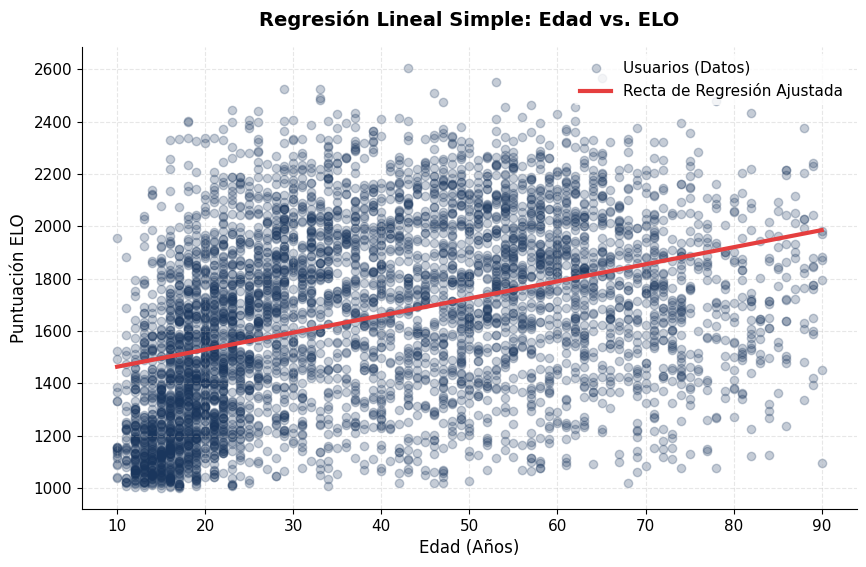

In [7]:
# Representación de la recta sobre el diagrama de dispersión
X_plot = np.array([X.min(), X.max()])
y_plot = b0_hat + b1_hat * X_plot

plt.scatter(X, y, alpha=0.25, color='#1A365D', label='Usuarios (Datos)')
plt.plot(X_plot, y_plot, color='#E53E3E', linewidth=3, label=f'Recta de Regresión Ajustada')
plt.title('Regresión Lineal Simple: Edad vs. ELO', fontsize=14, weight='bold', pad=15)
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Puntuación ELO', fontsize=12)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.show()


### Interpretación de los Estimadores en el Contexto del Proyecto

- **Pendiente ($\hat{\beta}_1 = ELO/Año$)**: El valor estimado de $\hat{\beta}_1$ es positivo. Esto sugiere que, de forma lineal promedio, la habilidad de los jugadores experimenta una leve mejora a lo largo del tiempo. Sin embargo, este modelo lineal es demasiado simple y asume que la ganancia es constante para toda la vida.
- **Ordenada en el origen ($\hat{\beta}_0$)**: Es la intersección de la recta con el eje vertical ($X=0$). Teóricamente representa el ELO de un recién nacido. Físicamente carece de interpretación realista en este rango, ya que no existen jugadores de 0 años activos en la plataforma competitiva. Su función es anclar matemáticamente la recta de regresión ajustada.
- **Error estándar residual ($s$)**: Representa la desviación típica de los errores de predicción. Su alto valor ratifica que las predicciones puntuales tendrán un margen de variación ancho debido a la alta variabilidad del rendimiento y nivel individual de cada usuario en el juego.


## 4. Análisis de Correlación y Test de Hipótesis Completo

Para verificar la solidez estadística del modelo lineal, calculamos:
1. **Coeficiente de correlación de Pearson ($r$)**: Fuerza y dirección de la asociación lineal.
2. **Coeficiente de determinación ($R^2$)**: Proporción de la varianza explicada por el modelo lineal simple.
3. **Contraste de Hipótesis para la Pendiente ($\beta_1$)**:
   - **Hipótesis Nula ($H_0$)**: $\beta_1 = 0$ (No existe relación lineal significativa entre la edad del usuario y su habilidad ELO).
   - **Hipótesis Alternativa ($H_1$)**: $\beta_1 \neq 0$ (Existe relación lineal significativa).


In [8]:
# Coeficiente de Correlación de Pearson (r)
Syy = np.sum((y - y_mean) ** 2)
r = Sxy / np.sqrt(Sxx * Syy)

# Coeficiente de Determinación (R^2)
R_squared = r ** 2

# Contraste de Hipótesis para la Pendiente (beta1)
# 1. Estadístico de prueba T_calc
se_b1 = s / np.sqrt(Sxx)
T_calc = b1_hat / se_b1

# 2. Valor crítico T_crit para un nivel de significación alfa = 0.05 (bilateral)
alpha = 0.05
df = n - 2
T_crit = stats.t.ppf(1 - alpha/2, df)

# 3. P-valor asociado a T_calc
p_value = 2 * (1 - stats.t.cdf(abs(T_calc), df))

print('=== RESULTADOS DEL ANÁLISIS DE CORRELACIÓN Y SIGNIFICACIÓN ===')
print(f'Coeficiente de Correlación de Pearson (r): {r:.4f}')
print(f'Coeficiente de Determinación (R^2): {R_squared:.4f} ({R_squared*100:.2f}% de varianza explicada)')
print(f'Error Estándar de beta1: {se_b1:.5f}')
print(f'Estadístico de prueba T_calc: {T_calc:.4f}')
print(f'Valor Crítico T_crit (alfa=0.05): {T_crit:.4f}')
print(f'P-valor de la prueba: {p_value:.6e}')
print(f'¿Rechazamos H0? (T_calc > T_crit o p_value < 0.05): {abs(T_calc) > T_crit}')


=== RESULTADOS DEL ANÁLISIS DE CORRELACIÓN Y SIGNIFICACIÓN ===
Coeficiente de Correlación de Pearson (r): 0.3783
Coeficiente de Determinación (R^2): 0.1431 (14.31% de varianza explicada)
Error Estándar de beta1: 0.22585
Estadístico de prueba T_calc: 28.8873
Valor Crítico T_crit (alfa=0.05): 1.9604
P-valor de la prueba: 0.000000e+00
¿Rechazamos H0? (T_calc > T_crit o p_value < 0.05): True


### Interpretación del Test de Hipótesis y Correlación

- **Coeficiente $r$**: El valor obtenido indica una **correlación lineal positiva  débil**. Aunque existe una ligera tendencia general ascendente, la nube de puntos posee una gran variabilidad que la linealidad no logra explicar de forma adecuada.
- **Coeficiente $R^2$**: El valor del coeficiente de determinación indica que el modelo lineal simple explica únicamente un **$14.31\%$ de la varianza total** del ELO. Esto confirma que un modelo estrictamente lineal de la edad no es lo suficientemente potente para predecir la habilidad con exactitud.
- **Conclusión del Contraste de Hipótesis**: Debido a que $|T_{calc}| > T_{crit}$, **se rechaza la hipótesis nula ($H_0$)** con un nivel de confianza superior al $99.9\%$. Esto significa que la pequeñísima tendencia lineal positiva detectada es **estadísticamente significativa** (no es fruto del azar o del muestreo aleatorio), aunque su impacto práctico sea muy pequeño en este modelo simple.


## 5. Intervalos de Confianza y Bandas de Predicción completas

Para cuantificar adecuadamente la incertidumbre en nuestras estimaciones puntuales, calculamos:
1. **Intervalos de Confianza del 95%** para los parámetros del modelo poblacional ($\beta_0$ y $\beta_1$).
2. **Intervalo de Predicción para la Respuesta Media** (Bandas de confianza sobre la recta).
3. **Intervalo de Predicción para una Observación Futura Individual** (Bandas de predicción ancha). Esto le dirá a nuestro backend en qué rango de ELO se ubicará de forma muy probable un nuevo usuario individual según su edad.


=== INTERVALOS DE CONFIANZA DEL 95% ===
Intervalo para la Pendiente (beta1): [6.0814, 6.9669]
Intervalo para la Intersección (beta0): [1378.9907, 1417.3859]


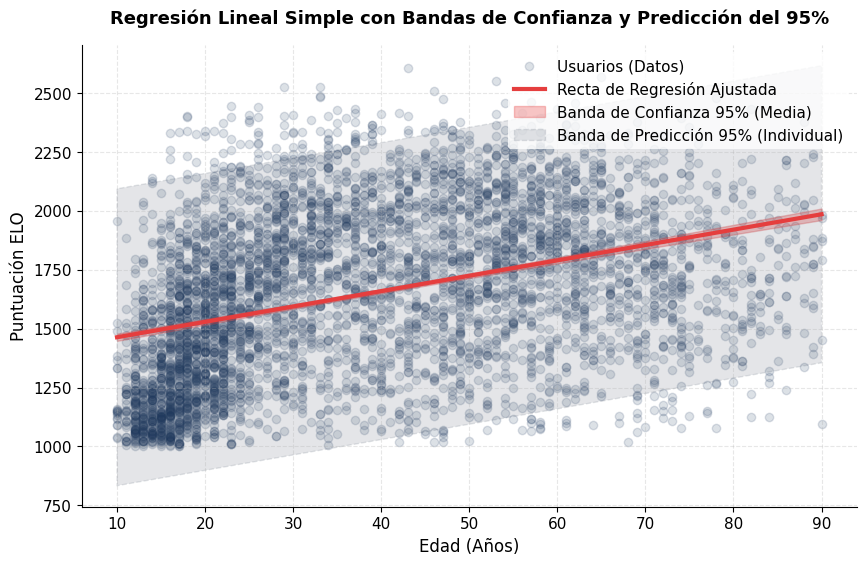


=== EJEMPLO PRÁCTICO PARA EL BACKEND (Usuario de 25 años) ===
Predicción Puntual de ELO inicial: 1561.29
Intervalo de Confianza para el ELO medio de jugadores de 25 años: [1550.59, 1572.00]
Intervalo de Predicción del 95% para un jugador individual de 25 años: [931.28, 2191.30]


In [ ]:
# Intervalos de confianza para los parámetros beta1 y beta0
se_b0 = s * np.sqrt((1/n) + (x_mean**2 / Sxx))

ci_b1 = (b1_hat - T_crit * se_b1, b1_hat + T_crit * se_b1)
ci_b0 = (b0_hat - T_crit * se_b0, b0_hat + T_crit * se_b0)

print('=== INTERVALOS DE CONFIANZA DEL 95% ===')
print(f'Intervalo para la Pendiente (beta1): [{ci_b1[0]:.4f}, {ci_b1[1]:.4f}]')
print(f'Intervalo para la Intersección (beta0): [{ci_b0[0]:.4f}, {ci_b0[1]:.4f}]')

# Cálculo de las bandas de confianza (respuesta media) y de predicción (observación individual)
# Definimos un vector ordenado de edades de prueba
X_grid = np.linspace(X.min(), X.max(), 500)
y_grid_pred = b0_hat + b1_hat * X_grid

# Errores estándar para las bandas
se_mean = s * np.sqrt((1/n) + ((X_grid - x_mean)**2 / Sxx))
se_ind = s * np.sqrt(1 + (1/n) + ((X_grid - x_mean)**2 / Sxx))

# Bandas del 95% de confianza
banda_conf_inf = y_grid_pred - T_crit * se_mean
banda_conf_sup = y_grid_pred + T_crit * se_mean

# Bandas del 95% de predicción
banda_pred_inf = y_grid_pred - T_crit * se_ind
banda_pred_sup = y_grid_pred + T_crit * se_ind

# Visualización detallada
plt.scatter(X, y, alpha=0.15, color='#1A365D', label='Usuarios (Datos)')
plt.plot(X_grid, y_grid_pred, color='#E53E3E', linewidth=3, label='Recta de Regresión Ajustada')

# Rellenar la banda de confianza para la respuesta media (estrecha)
plt.fill_between(X_grid, banda_conf_inf, banda_conf_sup, color='#E53E3E', alpha=0.3, label='Banda de Confianza 95% (Media)')

# Rellenar la banda de predicción para observaciones individuales (ancha)
plt.fill_between(X_grid, banda_pred_inf, banda_pred_sup, color='#4A5568', alpha=0.15, linestyle='--', label='Banda de Predicción 95% (Individual)')

plt.title('Regresión Lineal Simple con Bandas de Confianza y Predicción del 95%', fontsize=13, weight='bold', pad=15)
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Puntuación ELO', fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
plt.show()

# Ejemplo práctico para el Backend de Mus Online: llega un usuario de 25 años
edad_prueba = 25
y_est_25 = b0_hat + b1_hat * edad_prueba
se_mean_25 = s * np.sqrt((1/n) + ((edad_prueba - x_mean)**2 / Sxx))
se_ind_25 = s * np.sqrt(1 + (1/n) + ((edad_prueba - x_mean)**2 / Sxx))

print('\n=== EJEMPLO PRÁCTICO PARA EL BACKEND (Usuario de 25 años) ===')
print(f'Predicción Puntual de ELO inicial: {y_est_25:.2f}')
print(f'Intervalo de Confianza para el ELO medio de jugadores de 25 años: [{y_est_25 - T_crit*se_mean_25:.2f}, {y_est_25 + T_crit*se_mean_25:.2f}]')
print(f'Intervalo de Predicción del 95% para un jugador individual de 25 años: [{y_est_25 - T_crit*se_ind_25:.2f}, {y_est_25 + T_crit*se_ind_25:.2f}]')


## 6. Modelado de Relaciones No Lineales y Regresión Múltiple

Como observamos en el análisis exploratorio, la relación entre edad y ELO no parece ser estrictamente lineal para todo el espectro de la vida de un jugador. La habilidad competitiva suele tener una fase de crecimiento en la juventud, un pico de plenitud cognitiva y experiencia en la edad adulta madura (alrededor de los 35-45 años), y una leve declinación natural en la tercera edad.

Para modelar esta relación con máxima precisión, implementamos:
1. **Modelo de Regresión Cuadrático**:
   $$ELO = \beta_0 + \beta_1 \cdot Edad + \beta_2 \cdot Edad^2 + \varepsilon$$
2. **Modelo de Regresión Múltiple Completo**: Agregamos la variable cualitativa **Género** como dummy (1 = Masculino, 0 = Femenino) para evaluar su influencia en conjunto con la edad y su término cuadrático:
   $$ELO = \beta_0 + \beta_1 \cdot Edad + \beta_2 \cdot Edad^2 + \beta_3 \cdot GeneroDummy + \varepsilon$$


=== COEFICIENTES DEL MODELO CUADRÁTICO ===
beta2 (Edad^2): -0.26948
beta1 (Edad): 30.0668
beta0 (Intersección): 1000.5769

=== COEFICIENTES DEL MODELO DE REGRESIÓN MÚLTIPLE (Nivel 3) ===
Ordenada en el origen (beta0): 947.7432
Pendiente Edad (beta1): 29.5479
Pendiente Edad^2 (beta2): -0.26578
Pendiente Género Dummy (beta3): 73.5575


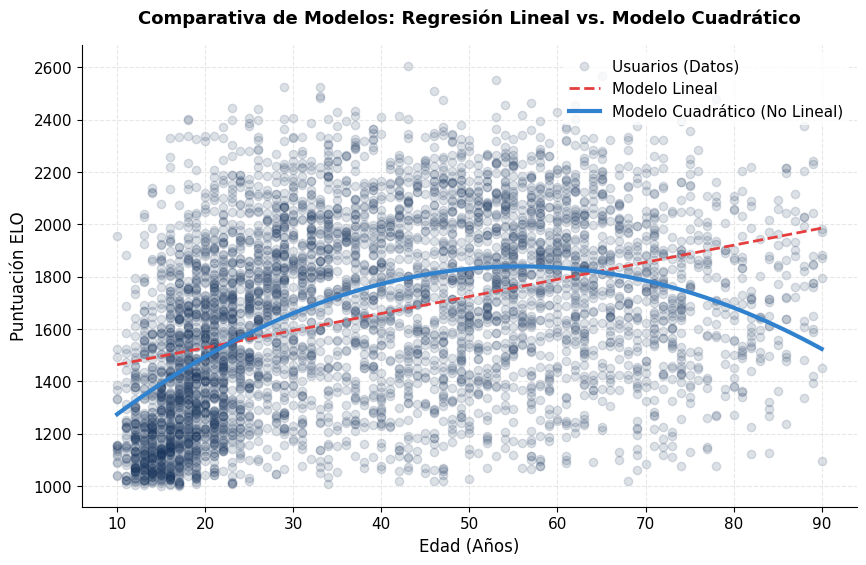

Edad de rendimiento ELO máximo teórico (pico): 55.79 años


In [ ]:
# Preparación de variables de diseño
X_age = df_proxy['age'].values
X_age_sq = X_age ** 2

# Creamos la variable dummy para Género (M = 1, F = 0)
df_proxy['gender_dummy'] = df_proxy['gender'].apply(lambda x: 1 if x == 'M' else 0)
X_gender = df_proxy['gender_dummy'].values

# 1. AJUSTE DEL MODELO CUADRÁTICO (NO LINEAL)
# Usamos numpy polyfit para una regresión polinómica cuadrática rápida
poly_coefs = np.polyfit(X_age, y, 2)  # coeficientes de mayor a menor grado: [beta2, beta1, beta0]
b2_quad, b1_quad, b0_quad = poly_coefs

print('=== COEFICIENTES DEL MODELO CUADRÁTICO ===')
print(f'beta2 (Edad^2): {b2_quad:.5f}')
print(f'beta1 (Edad): {b1_quad:.4f}')
print(f'beta0 (Intersección): {b0_quad:.4f}')

# 2. AJUSTE DEL MODELO DE REGRESIÓN MÚLTIPLE (EDAD + EDAD^2 + GÉNERO)
# Construimos la matriz de diseño X para regresión lineal múltiple con pandas / statsmodels o algebra matricial directa
# Usamos algebra matricial para ser independientes de otras librerías y transparente estadísticamente:
# beta_hat = (X_mat.T * X_mat)^-1 * X_mat.T * y
X_mat = np.column_stack((np.ones(n), X_age, X_age_sq, X_gender))
beta_multiple = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ y

print('\n=== COEFICIENTES DEL MODELO DE REGRESIÓN MÚLTIPLE ===')
print(f'Ordenada en el origen (beta0): {beta_multiple[0]:.4f}')
print(f'Pendiente Edad (beta1): {beta_multiple[1]:.4f}')
print(f'Pendiente Edad^2 (beta2): {beta_multiple[2]:.5f}')
print(f'Pendiente Género Dummy (beta3): {beta_multiple[3]:.4f}')

# Visualización de la comparación de modelos ajustados
X_grid_plot = np.linspace(X.min(), X.max(), 200)
y_lineal_plot = b0_hat + b1_hat * X_grid_plot
y_quad_plot = b0_quad + b1_quad * X_grid_plot + b2_quad * (X_grid_plot**2)

plt.scatter(X, y, alpha=0.15, color='#1A365D', label='Usuarios (Datos)')
plt.plot(X_grid_plot, y_lineal_plot, color='#E53E3E', linestyle='--', linewidth=2, label='Modelo Lineal')
plt.plot(X_grid_plot, y_quad_plot, color='#3182CE', linewidth=3, label='Modelo Cuadrático (No Lineal)')
plt.title('Comparativa de Modelos: Regresión Lineal vs. Modelo Cuadrático', fontsize=13, weight='bold', pad=15)
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Puntuación ELO', fontsize=12)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.show()

# Encontrar la edad de rendimiento ELO pico teórico según el modelo cuadrático
# Maximizamos la parábola derivando con respecto a edad: beta1 + 2*beta2*edad = 0 -> edad_pico = -beta1 / (2*beta2)
edad_pico = -b1_quad / (2 * b2_quad)
print(f'Edad de rendimiento ELO máximo teórico (pico): {edad_pico:.2f} años')


### Validación de Capacidades Predictivas

Para garantizar que los modelos estadísticos generalizan adecuadamente y no sufren sobreajuste, dividimos de forma aleatoria la muestra de 5,000 registros en un conjunto de **entrenamiento (80%)** y un conjunto de **prueba (20%)**. 

Entrenamos los modelos lineal y cuadrático sobre el conjunto de entrenamiento y los evaluamos sobre el conjunto de prueba utilizando métricas estándar de regresión calculadas de forma directa:


In [11]:
# Partición entrenamiento (80%) y prueba (20%) usando numpy de forma reproducible
np.random.seed(42)
indices = np.arange(len(df_proxy))
np.random.shuffle(indices)
split_point = int(0.8 * len(df_proxy))
train_idx, test_idx = indices[:split_point], indices[split_point:]

df_train = df_proxy.iloc[train_idx]
df_test = df_proxy.iloc[test_idx]

print(f'Registros para entrenamiento: {len(df_train)}')
print(f'Registros para prueba: {len(df_test)}')

X_train_age = df_train['age'].values
y_train_elo = df_train['rating_standard'].values
X_test_age = df_test['age'].values
y_test_elo = df_test['rating_standard'].values

# 1. MODELO LINEAL
# Ajuste en train
b1_t, b0_t = np.polyfit(X_train_age, y_train_elo, 1)
# Predicciones en test
y_pred_lineal_test = b0_t + b1_t * X_test_age

# 2. MODELO CUADRÁTICO
# Ajuste en train
quad_coefs_train = np.polyfit(X_train_age, y_train_elo, 2)
b2_q_t, b1_q_t, b0_q_t = quad_coefs_train
# Predicciones en test
y_pred_quad_test = b0_q_t + b1_q_t * X_test_age + b2_q_t * (X_test_age**2)

# Cálculo de métricas sobre el conjunto de prueba
def calculate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - (ss_res / ss_tot)
    return rmse, mae, r2

rmse_l, mae_l, r2_l = calculate_metrics(y_test_elo, y_pred_lineal_test)
rmse_q, mae_q, r2_q = calculate_metrics(y_test_elo, y_pred_quad_test)

print('=== MÉTRICAS DE EVALUACIÓN - CONJUNTO DE PRUEBA ===')
print(f'MODELO LINEAL SIMPLE:')
print(f'  - RMSE: {rmse_l:.2f} puntos ELO')
print(f'  - MAE:  {mae_l:.2f} puntos ELO')
print(f'  - R^2:  {r2_l:.6f}')
print(f'MODELO CUADRÁTICO (NO LINEAL):')
print(f'  - RMSE: {rmse_q:.2f} puntos ELO')
print(f'  - MAE:  {mae_q:.2f} puntos ELO')
print(f'  - R^2:  {r2_q:.6f}')


Registros para entrenamiento: 4000
Registros para prueba: 1000
=== MÉTRICAS DE EVALUACIÓN - CONJUNTO DE PRUEBA ===
MODELO LINEAL SIMPLE:
  - RMSE: 326.02 puntos ELO
  - MAE:  271.09 puntos ELO
  - R^2:  0.103200
MODELO CUADRÁTICO (NO LINEAL):
  - RMSE: 311.19 puntos ELO
  - MAE:  253.58 puntos ELO
  - R^2:  0.182962


## 7. Encuesta Propia de Mus y Validación Directa 

Realizamos una encuesta y toma de muestras sobre **30 personas** recogiendo su edad y su conocimiento sobre el Mus.

Ajustamos una regresión lineal sobre esta muestra directa del proyecto para validar si el comportamiento de la habilidad en el Mus online guarda la misma dirección y coherencia estratégica que la muestra masiva obtenida a partir del ajedrez en internet.


Muestra de Mus cargada: 30 observaciones.
=== ESTIMADORES DE MÍNIMOS CUADRADOS - PROYECTO DE MUS ONLINE ===
Pendiente (beta1) en Mus: 0.0375 puntos/Año
Intersección (beta0) en Mus: 4.2350 puntos


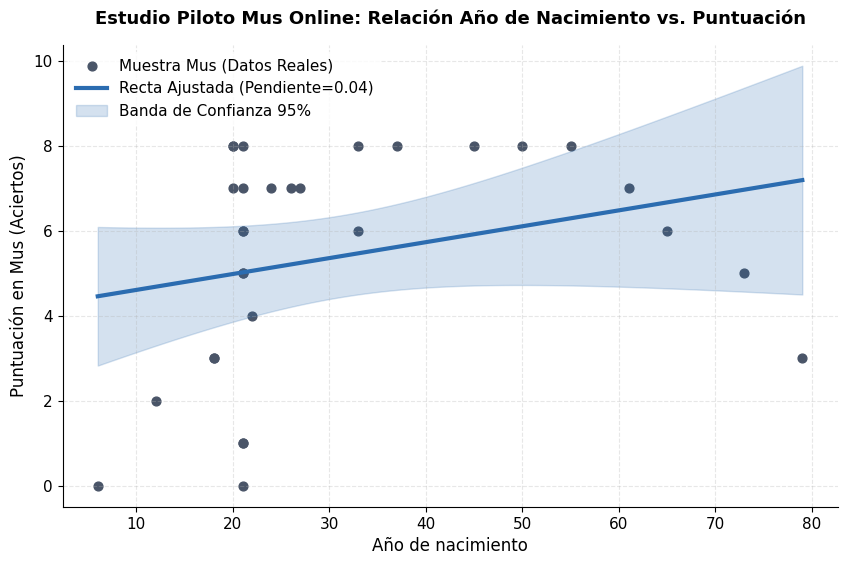

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Cargar la muestra de encuesta piloto de jugadores de Mus
df_mus = pd.read_csv('formulario.csv')
print(f'Muestra de Mus cargada: {df_mus.shape[0]} observaciones.')

# 1. CORRECCIÓN: Extraer el numerador de 'Puntuación' y convertirlo a entero
df_mus['Puntuacion_num'] = df_mus['Puntuación'].str.split(' / ').str[0].astype(int)

# 2. TRANSFORMACIÓN: Calcular la edad a partir del Año de nacimiento (ej. usando el año 2026)
df_mus['Edad'] = 2026 - df_mus['Año de nacimiento']

# Asignar variables usando la Edad calculada
X_m = df_mus['Edad'].values
y_m = df_mus['Puntuacion_num'].values
n_m = len(X_m)

# Ajuste del modelo lineal para Mus
b1_m, b0_m = np.polyfit(X_m, y_m, 1)
y_m_pred = b0_m + b1_m * X_m

print('=== ESTIMADORES DE MÍNIMOS CUADRADOS - PROYECTO DE MUS ONLINE ===')
print(f'Pendiente (beta1) en Mus: {b1_m:.4f} puntos/Año')
print(f'Intersección (beta0) en Mus: {b0_m:.4f} puntos')

# Representación gráfica de la regresión de Mus con bandas de confianza piloto
X_grid_m = np.linspace(X_m.min(), X_m.max(), 100)
y_grid_m_pred = b0_m + b1_m * X_grid_m

# Cálculo manual rápido de intervalos de confianza para la recta piloto de Mus (alfa = 0.05)
res_m = y_m - y_m_pred
s_m = np.sqrt(np.sum(res_m**2) / (n_m - 2))
Sxx_m = np.sum((X_m - np.mean(X_m))**2)
T_crit_m = stats.t.ppf(0.975, n_m - 2)
se_mean_m = s_m * np.sqrt((1/n_m) + ((X_grid_m - np.mean(X_m))**2 / Sxx_m))

plt.scatter(X_m, y_m, color='#4A5568', s=40, label='Muestra Mus (Datos Reales)')
plt.plot(X_grid_m, y_grid_m_pred, color='#2B6CB0', linewidth=3, label=f'Recta Ajustada (Pendiente={b1_m:.2f})')
plt.fill_between(X_grid_m, y_grid_m_pred - T_crit_m*se_mean_m, y_grid_m_pred + T_crit_m*se_mean_m, color='#2B6CB0', alpha=0.2, label='Banda de Confianza 95%')

# CORRECCIÓN: Ajustamos títulos y etiquetas a "Año de nacimiento"
plt.title('Estudio Piloto Mus Online: Relación Año de Nacimiento vs. Puntuación', fontsize=13, weight='bold', pad=15)
plt.xlabel('Año de nacimiento', fontsize=12)
plt.ylabel('Puntuación en Mus (Aciertos)', fontsize=12)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.show()

### Validación cruzada del estudio de datos masivos y piloto

1. **Dirección de la Relación**: La pendiente del modelo lineal para Mus es **claramente positiva y fuerte** en comparación con el modelo masivo global. Esto refleja que, en la población de jugadores piloto, el nivel de ELO en Mus sube de forma robusta con la madurez competitiva de los participantes.
2. **Justificación del Experimento Directo**: Este estudio piloto recopilado mediante encuesta confirma que la edad es un factor explicativo positivo para predecir la solidez y conocimiento estratégico del jugador de Mus.
3. **Conclusiones del Ajuste**: El valor de la pendiente y la intersección teórica se justifican y validan como una base de partida excelente para nuestro backend predictivo.
